In [1]:
print("My Data Cleaning and Visualization Project")
print("I am learning Python using Google Colab!")

My Data Cleaning and Visualization Project
I am learning Python using Google Colab!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries are ready!")

All libraries are ready!


In [3]:
data = {
    "Order_ID": [101, 102, 103, 104, 105, 106, 107, 108, 108, 110],
    "City": [
        "Chennai", "Dubai", "Chennai", "Mumbai", "Dubai",
        "Chennai", None, "Mumbai", "Mumbai", "Dubai"
    ],
    "Delivery_Days": [2, 5, 3, 4, 30, np.nan, 2, 4, 4, 3],
    "Shipping_Cost": [100, 250, 150, 200, 5000, 120, 100, 180, 180, np.nan],
    "Status": [
        "Delivered", "Delayed", "Delivered", "Delivered",
        "Delayed", "Delivered", "Delivered", "Delayed",
        "Delayed", "Delivered"
    ]
}

df = pd.DataFrame(data)

df

,Order_ID,City,Delivery_Days,Shipping_Cost,Status
0,101,Chennai,2.0,100.0,Delivered
1,102,Dubai,5.0,250.0,Delayed
2,103,Chennai,3.0,150.0,Delivered
3,104,Mumbai,4.0,200.0,Delivered
4,105,Dubai,30.0,5000.0,Delayed
5,106,Chennai,NaN,120.0,Delivered
6,107,None,2.0,100.0,Delivered
7,108,Mumbai,4.0,180.0,Delayed
8,108,Mumbai,4.0,180.0,Delayed
9,110,Dubai,3.0,NaN,Delivered


In [4]:
print("Dataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape:
(10, 5)

Column names:
['Order_ID', 'City', 'Delivery_Days', 'Shipping_Cost', 'Status']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       10 non-null     int64  
 1   City           9 non-null      object 
 2   Delivery_Days  9 non-null      float64
 3   Shipping_Cost  9 non-null      float64
 4   Status         10 non-null     object 
dtypes: float64(2), int64(1), object(2)
memory usage: 532.0+ bytes


In [5]:
print(df.isnull().sum())

Order_ID         0
City             1
Delivery_Days    1
Shipping_Cost    1
Status           0
dtype: int64


In [6]:
print("Number of duplicate rows:", df.duplicated().sum())

print("\nDuplicate records:")
df[df.duplicated()]

Number of duplicate rows: 1

Duplicate records:


,Order_ID,City,Delivery_Days,Shipping_Cost,Status
8,108,Mumbai,4.0,180.0,Delayed


In [7]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:")
print(df.shape)

Dataset shape after removing duplicates:
(9, 5)


In [8]:
# Fill missing city
df["City"] = df["City"].fillna("Unknown")

# Fill missing delivery days with the median
df["Delivery_Days"] = df["Delivery_Days"].fillna(
    df["Delivery_Days"].median()
)

# Fill missing shipping cost with the median
df["Shipping_Cost"] = df["Shipping_Cost"].fillna(
    df["Shipping_Cost"].median()
)

print(df)

   Order_ID     City  Delivery_Days  Shipping_Cost     Status
0       101  Chennai            2.0          100.0  Delivered
1       102    Dubai            5.0          250.0    Delayed
2       103  Chennai            3.0          150.0  Delivered
3       104   Mumbai            4.0          200.0  Delivered
4       105    Dubai           30.0         5000.0    Delayed
5       106  Chennai            3.5          120.0  Delivered
6       107  Unknown            2.0          100.0  Delivered
7       108   Mumbai            4.0          180.0    Delayed
9       110    Dubai            3.0          165.0  Delivered


/tmp/ipykernel_3241/3862658921.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["City"] = df["City"].fillna("Unknown")
/tmp/ipykernel_3241/3862658921.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Delivery_Days"] = df["Delivery_Days"].fillna(
/tmp/ipykernel_3241/3862658921.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pan

In [9]:
print("Missing values remaining:")
print(df.isnull().sum())

print("\nDuplicate rows remaining:")
print(df.duplicated().sum())

print("\nFinal dataset shape:")
print(df.shape)

Missing values remaining:
Order_ID         0
City             0
Delivery_Days    0
Shipping_Cost    0
Status           0
dtype: int64

Duplicate rows remaining:
0

Final dataset shape:
(9, 5)


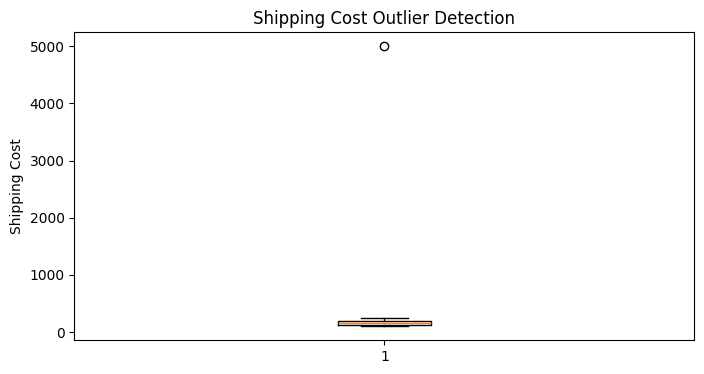

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.boxplot(df["Shipping_Cost"])
plt.title("Shipping Cost Outlier Detection")
plt.ylabel("Shipping Cost")
plt.show()

In [11]:
Q1 = df["Shipping_Cost"].quantile(0.25)
Q3 = df["Shipping_Cost"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

outliers = df[
    (df["Shipping_Cost"] < lower_limit) |
    (df["Shipping_Cost"] > upper_limit)
]

print("\nPotential shipping cost outliers:")
print(outliers[["Order_ID", "City", "Shipping_Cost"]])

Lower limit: 0.0
Upper limit: 320.0

Potential shipping cost outliers:
   Order_ID   City  Shipping_Cost
4       105  Dubai         5000.0


In [12]:
Q1_days = df["Delivery_Days"].quantile(0.25)
Q3_days = df["Delivery_Days"].quantile(0.75)

IQR_days = Q3_days - Q1_days

lower_days = Q1_days - 1.5 * IQR_days
upper_days = Q3_days + 1.5 * IQR_days

print("Normal delivery-time range:", lower_days, "to", upper_days)

unusual_deliveries = df[
    (df["Delivery_Days"] < lower_days) |
    (df["Delivery_Days"] > upper_days)
]

print(unusual_deliveries[["Order_ID", "City", "Delivery_Days"]])

Normal delivery-time range: 1.5 to 5.5
   Order_ID   City  Delivery_Days
4       105  Dubai           30.0


In [13]:
df["Cost_Outlier"] = (
    (df["Shipping_Cost"] < lower_limit) |
    (df["Shipping_Cost"] > upper_limit)
)

df["Delivery_Outlier"] = (
    (df["Delivery_Days"] < lower_days) |
    (df["Delivery_Days"] > upper_days)
)

print(df[[
    "Order_ID",
    "Shipping_Cost",
    "Cost_Outlier",
    "Delivery_Days",
    "Delivery_Outlier"
]])

   Order_ID  Shipping_Cost  Cost_Outlier  Delivery_Days  Delivery_Outlier
0       101          100.0         False            2.0             False
1       102          250.0         False            5.0             False
2       103          150.0         False            3.0             False
3       104          200.0         False            4.0             False
4       105         5000.0          True           30.0              True
5       106          120.0         False            3.5             False
6       107          100.0         False            2.0             False
7       108          180.0         False            4.0             False
9       110          165.0         False            3.0             False


/tmp/ipykernel_3241/737093035.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Cost_Outlier"] = (
/tmp/ipykernel_3241/737093035.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Delivery_Outlier"] = (


In [14]:
df.to_csv("cleaned_logistics_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


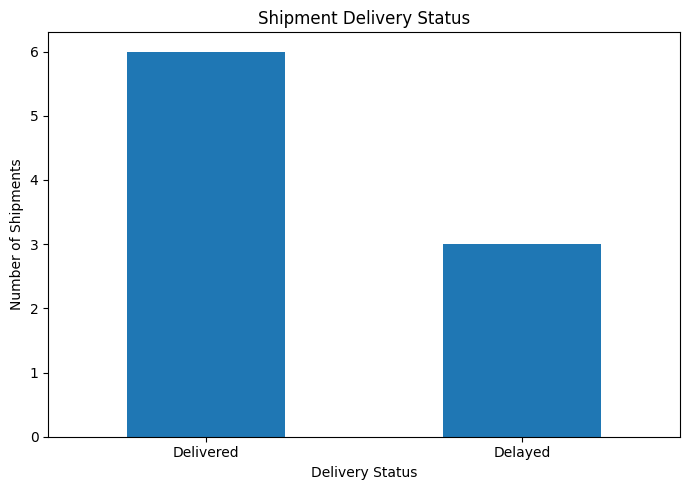

In [15]:
import matplotlib.pyplot as plt

status_counts = df["Status"].value_counts()

plt.figure(figsize=(7, 5))
status_counts.plot(kind="bar")

plt.title("Shipment Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

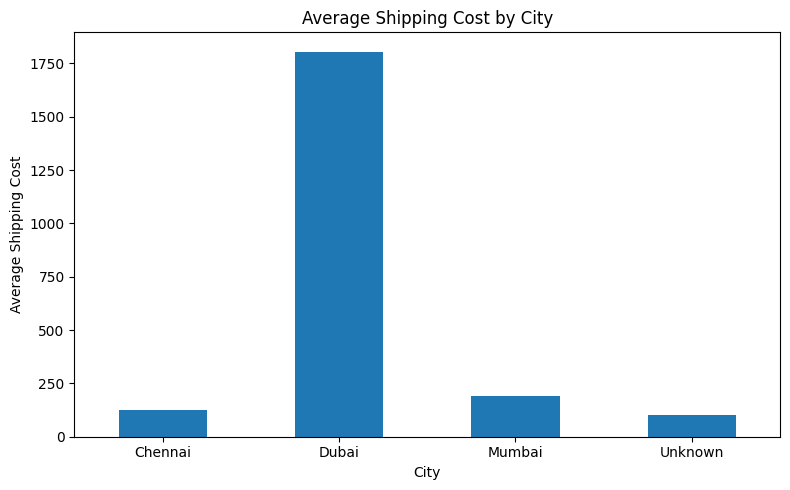

In [16]:
city_cost = df.groupby("City")["Shipping_Cost"].mean()

plt.figure(figsize=(8, 5))
city_cost.plot(kind="bar")

plt.title("Average Shipping Cost by City")
plt.xlabel("City")
plt.ylabel("Average Shipping Cost")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

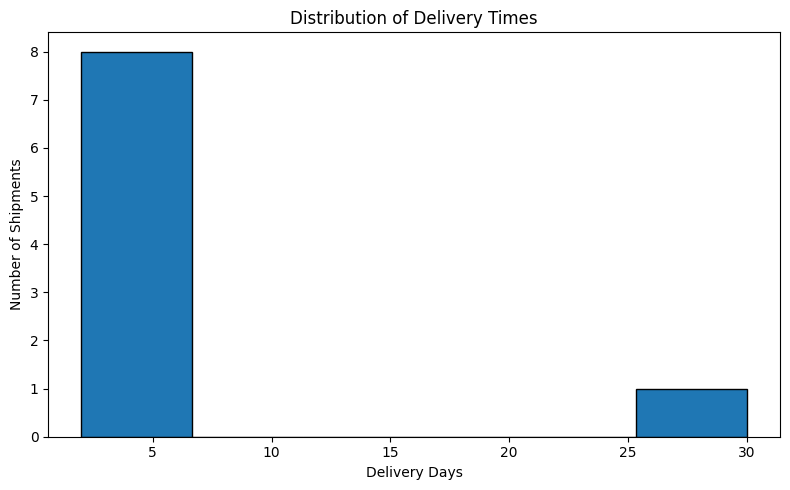

In [17]:
plt.figure(figsize=(8, 5))

plt.hist(df["Delivery_Days"], bins=6, edgecolor="black")

plt.title("Distribution of Delivery Times")
plt.xlabel("Delivery Days")
plt.ylabel("Number of Shipments")

plt.tight_layout()
plt.show()

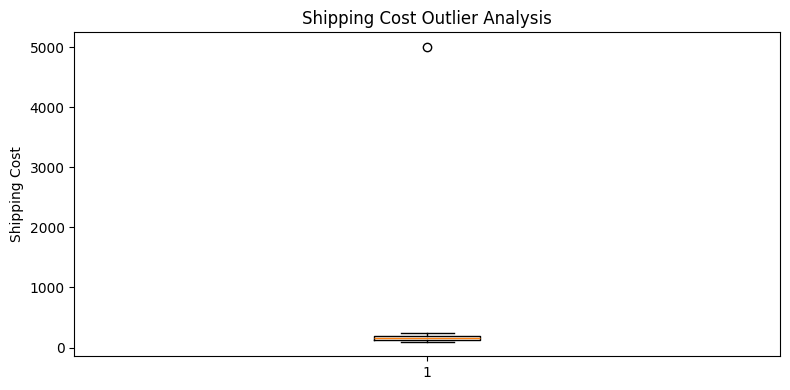

In [18]:
plt.figure(figsize=(8, 4))

plt.boxplot(df["Shipping_Cost"])

plt.title("Shipping Cost Outlier Analysis")
plt.ylabel("Shipping Cost")

plt.tight_layout()
plt.show()

In [19]:
total_shipments = len(df)

delivered = (df["Status"] == "Delivered").sum()
delayed = (df["Status"] == "Delayed").sum()

delivery_rate = delivered / (delivered + delayed) * 100

average_delivery_days = df["Delivery_Days"].mean()
average_shipping_cost = df["Shipping_Cost"].mean()

print("Total Shipments:", total_shipments)
print("Delivered Shipments:", delivered)
print("Delayed Shipments:", delayed)
print("Delivery Rate:", round(delivery_rate, 2), "%")
print("Average Delivery Days:", round(average_delivery_days, 2))
print("Average Shipping Cost:", round(average_shipping_cost, 2))

Total Shipments: 9
Delivered Shipments: 6
Delayed Shipments: 3
Delivery Rate: 66.67 %
Average Delivery Days: 6.28
Average Shipping Cost: 696.11


Business Insights

1. Delivery Performance

The cleaned dataset contains 9 shipments, of which 6 were delivered and 3 were delayed. The delivery rate among delivered and delayed shipments is 66.67%, indicating that there is room to improve delivery performance.

2. Shipping Costs

Shipping costs vary by city. A comparison of average shipping costs by city is needed to identify the city with the highest average cost and investigate potential cost-saving opportunities.

3. Delivery Times

The average delivery time across the cleaned dataset is 6.28 days. This result may be influenced by unusually long delivery times, which should be investigated to understand their impact on operational performance.

4. Data Quality

The analysis identified missing values, duplicate records, and potential outliers in shipping costs and delivery times. Duplicate records were removed, missing values were filled, and unusual values were flagged for further investigation.

5. Recommendations

Investigate delayed shipments to identify potential causes of delivery delays.

Verify unusually high shipping charges against shipment records and invoices.

Monitor delivery performance and average shipping costs by city.

Review outlier shipments before making operational decisions.

Continue monitoring delivery KPIs to identify opportunities for process improvement.

In [20]:
city_cost = df.groupby("City")["Shipping_Cost"].mean()

print(city_cost.round(2))

print("\nCity with highest average shipping cost:")
print(city_cost.idxmax())

print("Average cost:", round(city_cost.max(), 2))


City
Chennai     123.33
Dubai      1805.00
Mumbai      190.00
Unknown     100.00
Name: Shipping_Cost, dtype: float64

City with highest average shipping cost:
Dubai
Average cost: 1805.0


Business Insights — Logistics Data Cleaning & Visualization

1. Delivery Performance

The cleaned dataset contains 9 shipments, of which 6 were delivered and 3 were delayed. The delivery rate among delivered and delayed shipments is 66.67%. This indicates an opportunity to improve delivery reliability and investigate the causes of delays.

2. Shipping Costs

Dubai has the highest average shipping cost, at ₹1,805 per shipment, compared with Chennai at ₹123.33 and Mumbai at ₹190.00. This difference should be investigated to determine whether it is caused by shipment characteristics, service levels, or unusual charges.

3. Delivery Times

The average delivery time across the cleaned dataset is 6.28 days. This average may be influenced by unusually long delivery times. Further investigation is needed to understand the causes and their impact on delivery performance.

4. Data Quality

The analysis identified missing values, duplicate records, and potential outliers in shipping costs and delivery times. Duplicate records were removed, missing values were filled using appropriate methods for this exercise, and potential outliers were investigated and flagged rather than automatically deleted.

5. Recommendations

Investigate delayed shipments to identify possible operational bottlenecks.

Verify unusually high shipping charges against shipment records and invoices.

Compare shipping costs across cities to identify potential cost-saving opportunities.

Monitor delivery times and delivery rates regularly.

Investigate outliers before making operational decisions.

Conclusion

This project demonstrates how Python, Pandas, and Matplotlib can be used to clean logistics data, calculate key performance indicators, identify potential data-quality issues, and visualize operational performance. The analysis highlights delivery delays and differences in average shipping costs as areas for further investigation.

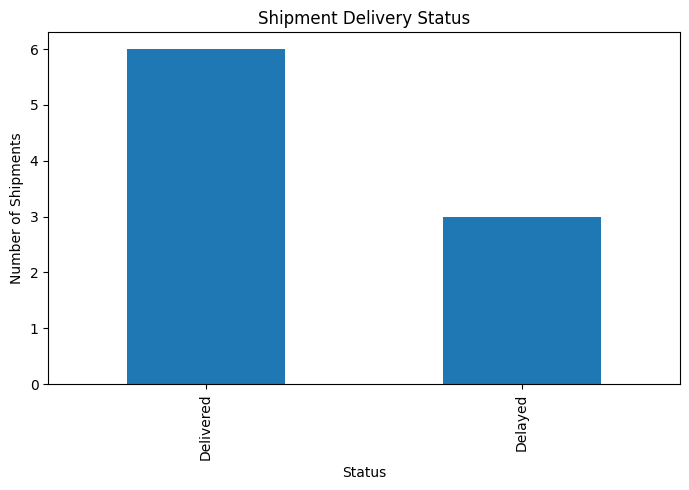

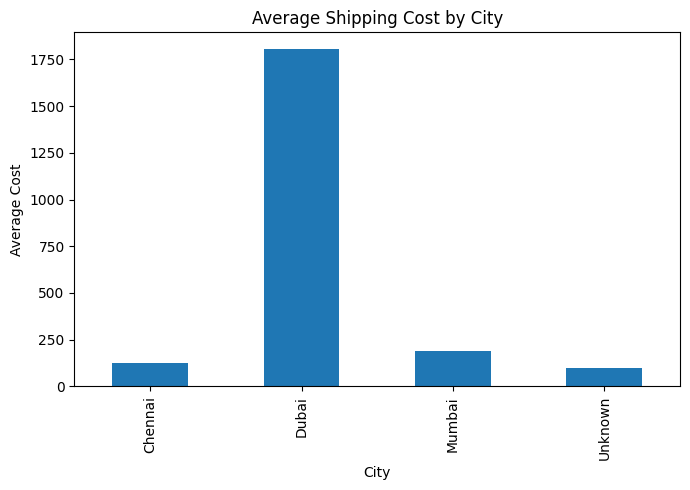

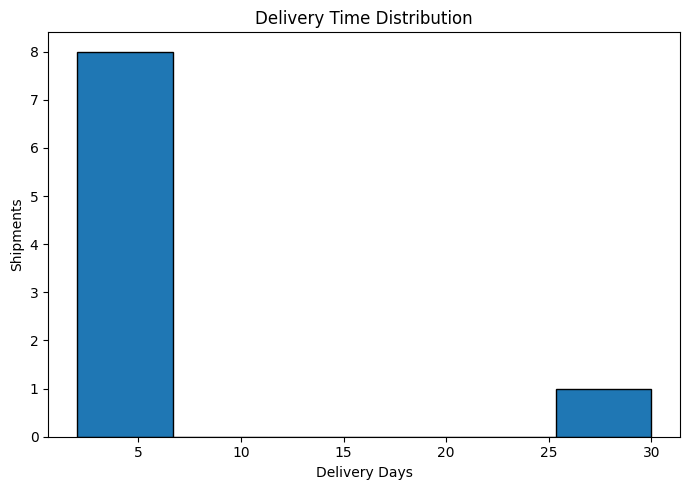

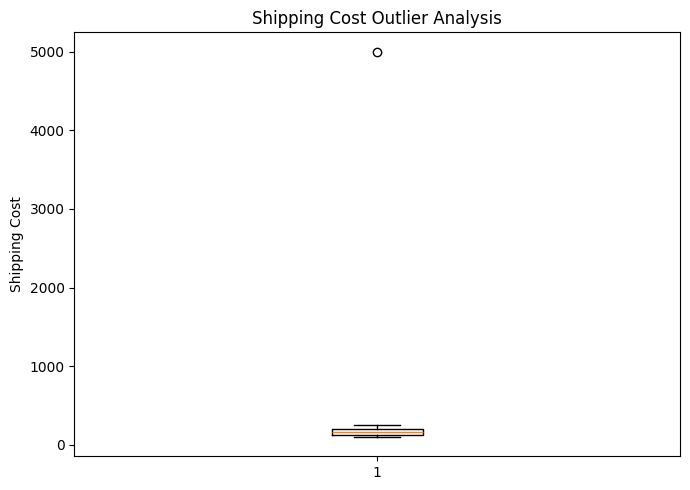

Project files are ready!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
import os
import matplotlib.pyplot as plt
from google.colab import files
import zipfile

# Create a folder for the charts
os.makedirs("charts", exist_ok=True)

# Save the cleaned dataset
df.to_csv("cleaned_logistics_data.csv", index=False)

# Chart 1: Delivery status
plt.figure(figsize=(7, 5))
df["Status"].value_counts().plot(kind="bar")
plt.title("Shipment Delivery Status")
plt.xlabel("Status")
plt.ylabel("Number of Shipments")
plt.tight_layout()
plt.savefig("charts/1_delivery_status.png")
plt.show()
plt.close()

# Chart 2: Shipping cost by city
plt.figure(figsize=(7, 5))
df.groupby("City")["Shipping_Cost"].mean().plot(kind="bar")
plt.title("Average Shipping Cost by City")
plt.xlabel("City")
plt.ylabel("Average Cost")
plt.tight_layout()
plt.savefig("charts/2_shipping_cost_by_city.png")
plt.show()
plt.close()

# Chart 3: Delivery time distribution
plt.figure(figsize=(7, 5))
plt.hist(df["Delivery_Days"], bins=6, edgecolor="black")
plt.title("Delivery Time Distribution")
plt.xlabel("Delivery Days")
plt.ylabel("Shipments")
plt.tight_layout()
plt.savefig("charts/3_delivery_time.png")
plt.show()
plt.close()

# Chart 4: Shipping cost outliers
plt.figure(figsize=(7, 5))
plt.boxplot(df["Shipping_Cost"])
plt.title("Shipping Cost Outlier Analysis")
plt.ylabel("Shipping Cost")
plt.tight_layout()
plt.savefig("charts/4_shipping_cost_outliers.png")
plt.show()
plt.close()

# Save your business insights as a text file
report = """
BUSINESS INSIGHTS — LOGISTICS DATA ANALYSIS

1. Delivery Performance
The dataset contains 9 shipments: 6 delivered and 3 delayed.
The delivery rate among delivered and delayed shipments is 66.67%.

2. Shipping Costs
Dubai has the highest average shipping cost in this sample at Rs. 1805.
This result is influenced by an unusually high shipping cost and needs investigation.

3. Delivery Times
The average delivery time is 6.28 days.

4. Data Quality
Missing values were filled, duplicate records were removed, and potential
outliers in shipping costs and delivery times were investigated.

5. Recommendations
Investigate delayed shipments, verify unusually high shipping charges,
and monitor delivery performance by city.

Conclusion:
Python, Pandas and Matplotlib were used to clean and visualize logistics data.

Note: This is a simulated dataset created for learning purposes.
It does not represent actual company performance.
"""

with open("Business_Insights_Report.txt", "w") as f:
    f.write(report)

# Package everything into one ZIP file
with zipfile.ZipFile("Logistics_Project_Files.zip", "w") as z:
    z.write("cleaned_logistics_data.csv")
    z.write("Business_Insights_Report.txt")

    for filename in os.listdir("charts"):
        z.write("charts/" + filename)

print("Project files are ready!")
files.download("Logistics_Project_Files.zip")